# IND320 - Part 3: Data quality

Development notebook, started 26 October 2026. Region boundaries and sample locations have been prepared. The full weather download and statistical analyses remain unfinished.

[GitHub](https://github.com/Sipan2/IND320-Sipan2) | [Streamlit](https://ind320-sipan2.streamlit.app/)


## 1. Region boundaries and spatial sampling

NVE Atlas identifies the electricity price areas as NO1–NO5. Its administrative region layer contains RS, RØ, RV, RM and RN. The separate NVE download portal was unavailable, so `region_data.py` retrieves the original GeoJSON from the published map services and exports shapefiles locally. The original responses, retrieval times and SHA-256 hashes are retained. These are locally exported shapefiles, rather than ZIP archives downloaded from the portal.

The script samples 1,000 points in each of the ten source regions. Sampling uses EPSG:3035, an equal-area projection, with a fixed seed. Every sampled point is checked against its source polygon before conversion to WGS84. The original administrative identifiers are preserved. Their mapping to the assignment's precipitation areas, including the stated RS+RØ and RM+RN unions, remains to be verified before those weather selections are implemented.

Sources: [electricity areas](https://gis3.nve.no/map/rest/services/Mapservices/Omradekonsesjoner/MapServer/8), [NVE regions](https://gis3.nve.no/map/rest/services/Mapservices/Administrasjon2/MapServer/0).


Prepared locations: 10000


Locations
region_type region           
electricity NO1          1000
            NO2          1000
            NO3          1000
            NO4          1000
            NO5          1000
nve_regions RM           1000
            RN           1000
            RS           1000
            RV           1000
            RØ           1000

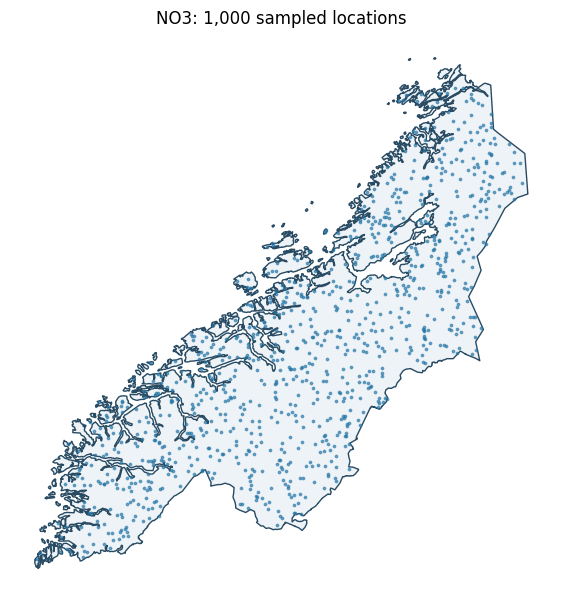

In [1]:
from pathlib import Path
import sys
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Resolve the project folder whether run from its root or notebooks directory.
project_root = Path.cwd() if Path("region_data.py").exists() else Path.cwd().parent
sys.path.insert(0, str(project_root))
points = pd.read_csv(project_root / "data/regions/sampled_locations.csv")
print("Prepared locations:", len(points))
display(points.groupby(["region_type", "region"]).size().rename("Locations").to_frame())

# Plot the NO3 sample against its actual polygon, using the same equal-area CRS.
areas = gpd.read_file(project_root / "data/regions/electricity.geojson").to_crs(3035)
no3 = areas.loc[areas.ElSpotOmr.eq("NO3")]
locations = points.loc[points.region_type.eq("electricity") & points.region.eq("NO3")]
sample = gpd.GeoDataFrame(locations, geometry=gpd.points_from_xy(locations.longitude, locations.latitude), crs=4326).to_crs(3035)
assert sample.within(no3.geometry.iloc[0]).all()
ax = no3.plot(color="#eef3f7", edgecolor="#284b63", figsize=(7, 8))
sample.plot(ax=ax, markersize=3, color="#2274a5", alpha=0.6)
ax.set_title("NO3: 1,000 sampled locations")
ax.set_axis_off()
plt.show()


## 2. Historical weather from ERA5

Implement a region-and-date download function using the saved coordinates. Retrieve hourly temperature and precipitation for NO3 in 2024. Explicitly select ERA5 rather than the default model blend. Cache responses and check timestamps, units, missing values, returned grid locations and spatial coverage before computing regional means. Test a small request before the full download.

Source: https://open-meteo.com/en/docs/historical-weather-api

A pilot request at sampled NO3 point 0 covers 1–2 January 2024: 48 hourly records with no missing temperature or precipitation values. This is a connection check at one location, not a regional average or the full 2024 dataset. The regional download function has not yet been tested at full scale.


In [2]:
from weather_data import download_weather

# Reuse the cached pilot response; the full-year regional download comes later.
pilot = download_weather("NO3", "2024-01-01", "2024-01-02", point_ids=[0])
assert len(pilot) == 48
assert pilot[["temperature_2m", "precipitation"]].notna().all().all()
print("Pilot records:", len(pilot))
display(pilot[["time_utc", "temperature_2m", "precipitation"]].head())


Pilot records: 48


,time_utc,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-14.0,0.0
1,2024-01-01 01:00:00+00:00,-14.3,0.0
2,2024-01-01 02:00:00+00:00,-14.3,0.0
3,2024-01-01 03:00:00+00:00,-14.6,0.0
4,2024-01-01 04:00:00+00:00,-14.6,0.0


## 3. Precipitation: DCT and SPC

Implement and test a function returning the original precipitation plot, robust SPC boundaries, marked outliers and numerical summaries. Expose the DCT frequency cut-off and threshold multiplier. Use high-pass residuals to estimate boundaries; do not plot the residual series.

The assignment refers to filtering precipitation but calls the result temperature variations (SATV). This wording is inconsistent. The provisional interpretation is to analyse precipitation residuals here, pending clarification.


## 4. Temperature: Local Outlier Factor

Implement and test a function returning a temperature plot and anomaly summaries. Set the default contamination to 0.01. Document the features, scaling and neighbourhood used by LOF.


## 5. Reservoir filling: STL

Implement and test STL decomposition with seasonal smoother, trend smoother and robust mode as parameters. Check weekly spacing and missing observations before choosing a seasonal period. Return the decomposition plot.


## 6. Reservoir filling: spectrogram

Use the same filling series as STL. Expose window length and overlap, validate their relationship, and label time and frequency units. Return and test the plot.


## 7. Streamlit integration

Keep the existing app address and data sources. Add one page with STL and spectrogram tabs, and one with SPC and LOF tabs. Connect weather selections to the relevant reservoir area selection. The Canvas app section is still labelled Under development and must be checked again before finalisation.


## 8. AI usage

Codex read the assignment and feedback, helped organise the repository, and wrote the initial region download, spatial sampling and weather access functions. It also helped draft the explanations. This statement will be updated to reflect subsequent work and the user's contributions.


## 9. Work log

Not written yet. Write 300–500 words based on the work actually completed, including notebook and Streamlit experience.
